In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Columns' description**

**survival** - Survival - 0 = No, 1 = Yes  
**pclass** - Ticket class - 1 = 1st, 2 = 2nd, 3 = 3rd  
**sex** - Sex	  
**Age**	- Age in years	  
**sibsp** - # of siblings / spouses aboard the Titanic	  
**parc** - # of parents / children aboard the Titanic	  
**ticket** - Ticket number	  
**fare** - Passenger fare	  
**cabin** - Cabin number	  
**embarked** - Port of Embarkation - C = Cherbourg, Q = Queenstown, S = Southampton  

In [23]:
titanic = pd.read_csv('titanic.csv')

In [24]:
titanic.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Визначення відсутніх даних

<Axes: >

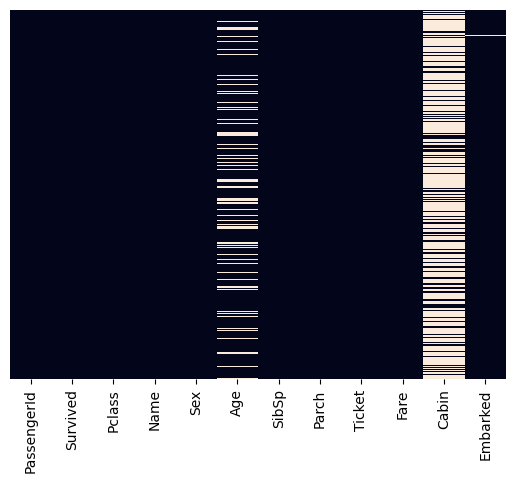

In [25]:
sns.heatmap(titanic.isnull(), yticklabels=False, cbar=False)

In [9]:
missing_values_count = titanic.isnull().sum()

missing_values_count

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Робота зі стовпцем Age

Бачимо, що різним Ticket Class притаманні характерні значення Age

<Axes: xlabel='Pclass', ylabel='Age'>

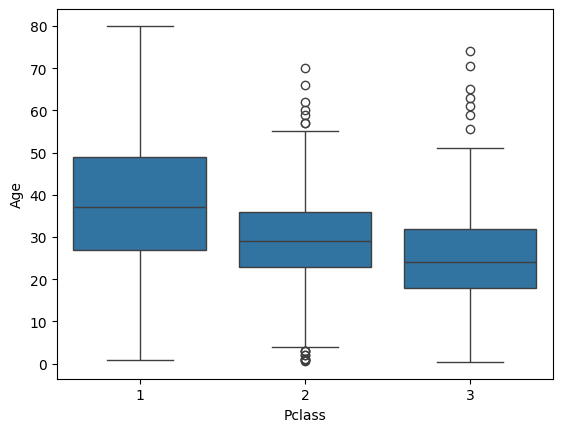

In [11]:
sns.boxplot(x='Pclass', y='Age', data=titanic)

Замінюємо пропущені значення на медіанні для кожного Ticket Class

In [36]:
def impute_age(cols):
    Age = cols.iloc[0]
    Pclass = cols.iloc[1]
    if pd.isnull(Age):
        if Pclass == 1:
            return titanic.loc[titanic['Pclass'] == 1, 'Age'].median()
        elif Pclass == 2:
            return titanic.loc[titanic['Pclass'] == 2, 'Age'].median()
        else:
            return titanic.loc[titanic['Pclass'] == 3, 'Age'].median()
    else: 
        return Age

In [26]:
titanic['Age'] = titanic[['Age', 'Pclass']].apply(impute_age, axis=1)

 ### Робота зі стовпцем Cabin

<Axes: >

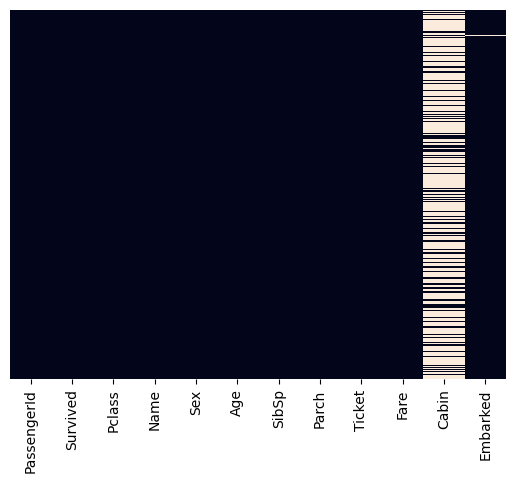

In [27]:
 sns.heatmap(titanic.isnull(), yticklabels=False, cbar=False)

Бачимо, що у нас дуже багато пропусків значень Cabin, тому я бачу два рішення для очищення цих даних:  
1. Повне видалення колонки Cabin. Оскільки така колонка лише одна, тому даними з неї можна знехтувати;
2. Класифікація колонки Cabin. Аби не видаляти цю колонку, можна записати пропущені дані як 0, а наявні як 1.

**Повне видалення стовпця Cabin**

In [30]:
titanic_cabin_dropped = titanic.drop('Cabin', axis=1)

In [31]:
titanic_cabin_dropped

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,24.0,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C


**Класифікація стовпця Cabin**

In [32]:
def cabin_cLassification(col):
    if pd.isnull(col):
        return 0
    else:
        return 1

In [34]:
titanic['Cabin'] = titanic['Cabin'].apply(cabin_cLassification)

In [35]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,0,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,1,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,0,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,1,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,0,S


### Робота зі стовпцем Embarked

<Axes: >

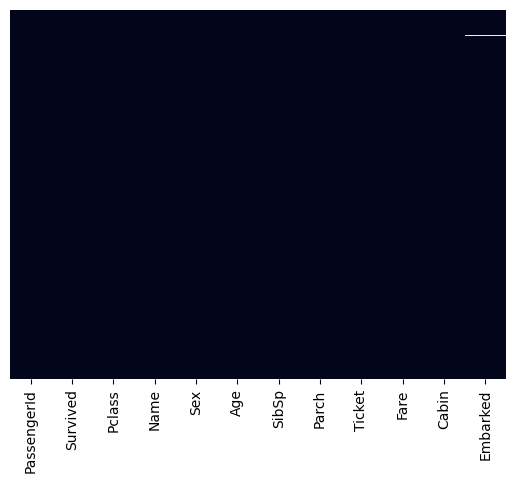

In [38]:
 sns.heatmap(titanic.isnull(), yticklabels=False, cbar=False)

Бачимо, що пропущених даних дуже мало (2 значення), тому рядками із цими даними можна просто знехтувати.

In [39]:
titanic.dropna(inplace=True)

### Результат

<Axes: >

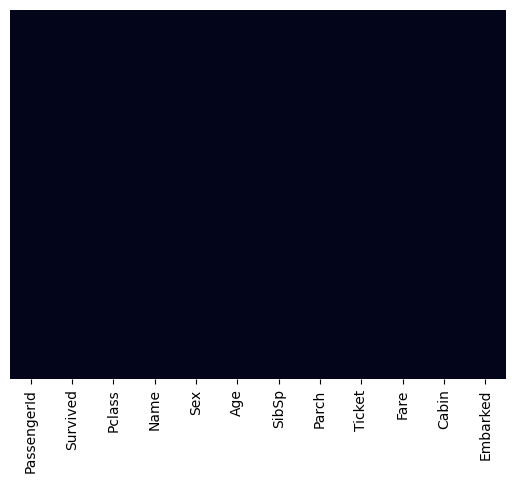

In [40]:
 sns.heatmap(titanic.isnull(), yticklabels=False, cbar=False)

In [41]:
missing_values_count = titanic.isnull().sum()

missing_values_count

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Тепер у датасеті повністю відсутні пропущені дані. 